<a href="https://colab.research.google.com/github/TreesaAbraham/svd-image-compression-MATH344L/blob/main/notebook/04_which_images.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/TreesaAbraham/svd-image-compression-MATH344L.git
import sys
sys.path.append('/content/svd-image-compression-MATH344L/src')

Cloning into 'svd-image-compression-MATH344L'...
remote: Enumerating objects: 184, done.
remote: Counting objects: 100% (184/184), done.
remote: Compressing objects: 100% (178/178), done.
remote: Total 184 (delta 91), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (184/184), 6.78 MiB | 13.41 MiB/s, done.
Resolving deltas: 100% (91/91), done.


Clones the GitHub repository to import the helper functions

In [2]:
from compress import rank_k_approx, rel_error, predicted_error, compression_ratio
import numpy as np
import matplotlib.pyplot as plt

Imports helper functions

In [3]:
def k_for_error(s, target):
  "Smallest k whose relative error is at most target"
  for k in range(1, len(s)+1):
    if predicted_error(s, k) <= target:
      return k

Loops through rank values k and returns the smallest k, where the predicted error is less than or equal to target

##Part 2

In [4]:
N = 256
i, j = np.meshgrid(np.arange(N), np.arange(N), indexing = "ij")

def stripes(angle, width = 16):
  "Black and white stripes, tilted by 'angle' degrees"
  t = np.deg2rad(angle)
  return 255.0 * (np.floor((i * np.cos(t) + j * np.sin(t)) / width) % 2)

rng = np.random.default_rng(0)
patterns = {
    "stripes, 0 deg": stripes(0),
    "stripes, 45 deg": stripes(45),
    "checkerboard": 255.0 * ((i // 32 + j // 32) % 2),
    "disk": 255.0 * ((i - N/2)**2 + (j-N/2)**2 < (N/3)**2),
    "noise": rng.integers(0, 256, size = (N, N)).astype(float),
}




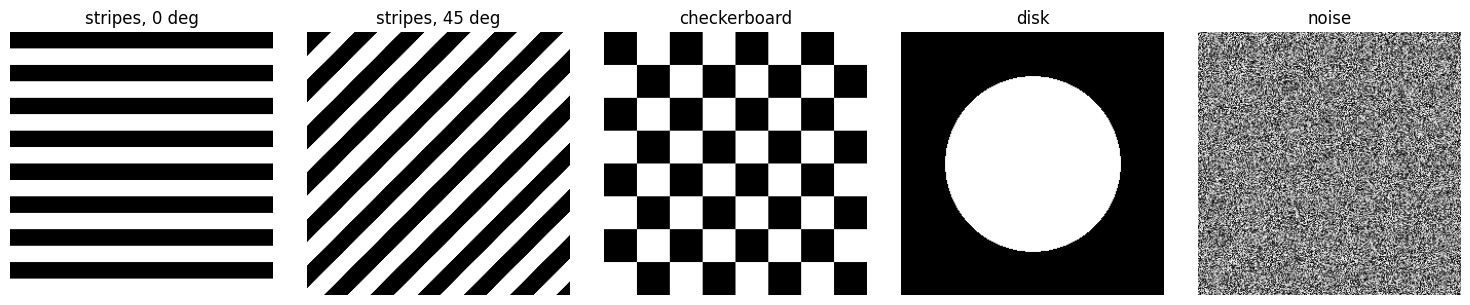

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, (name, P) in zip(axes, patterns.items()):
    ax.imshow(P, cmap="gray", vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

Creates two 256 x 256 arrays with i = row, and j = column

stripes converts angle to radians, projects each pixel along a direction, divide by the width, and alternates between 0 and 255

the patterns are the different images



Guess Ranks for Each

Horizontal Stripes = 1; these seem to be the most basic

45 Degree Stipes = no clue but should be much larger than 1 (maybe somewheere around the 100s?)

Checkerboard = 2

Disk = 32

Noise = 167

Best = horizontal stripe

Worst = Noise

In [5]:
for name, P in patterns.items():
  s = np.linalg.svd(P, compute_uv = False)
  k5 = k_for_error(s, 0.05)
  print(f"{name:16s} rank={np.linalg.matrix_rank(P): 3d} k for 5% = {k5:3d}"     f"ratio = {compression_ratio(N, N, k5): 6.2f}")

stripes, 0 deg   rank=  1 k for 5% =   1ratio =  127.75
stripes, 45 deg  rank= 182 k for 5% =  64ratio =   2.00
checkerboard     rank=  2 k for 5% =   2ratio =  63.88
disk             rank= 51 k for 5% =  26ratio =   4.91
noise            rank= 256 k for 5% = 198ratio =   0.65


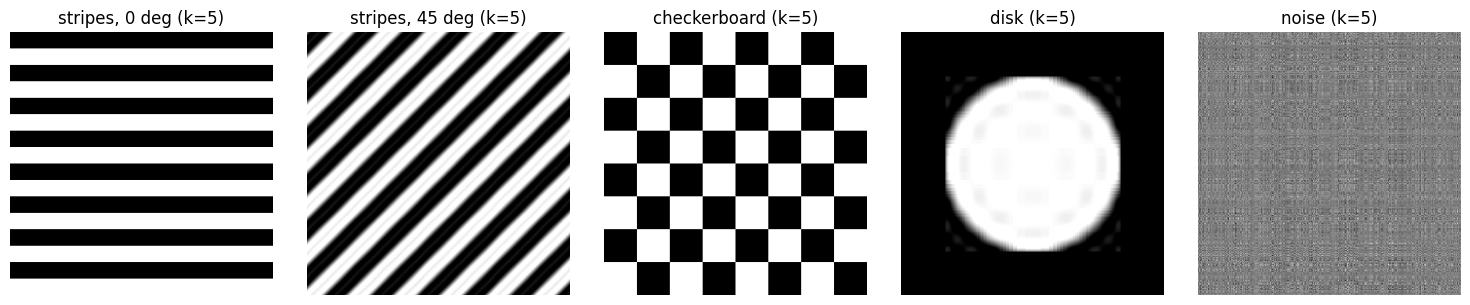

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, (name, P) in zip(axes, patterns.items()):
    approx = np.clip(rank_k_approx(P, 5), 0, 255)
    ax.imshow(approx, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{name} (k=5)")
    ax.axis("off")
plt.tight_layout()
plt.show()

Computes singular values, finds number of singular values to stay within 5% target error. Prints matrix rank and the compression ratio

##Part 3

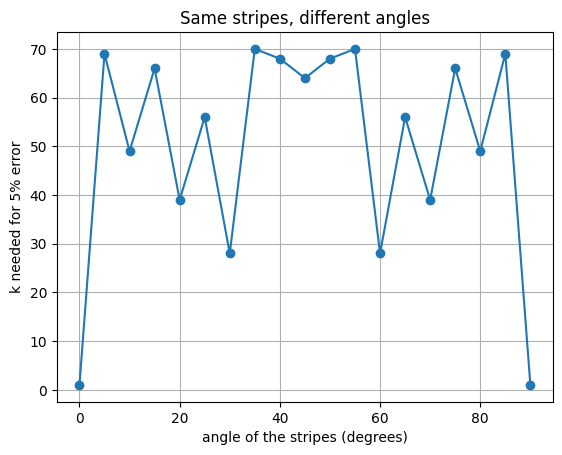

In [7]:
angles = np.arange(0, 91, 5)
ks = [k_for_error(np.linalg.svd(stripes(a), compute_uv = False), 0.05) for a in angles]

plt.plot(angles, ks, "o-")
plt.xlabel("angle of the stripes (degrees)")
plt.ylabel("k needed for 5% error")
plt.title("Same stripes, different angles")
plt.grid()
plt.savefig("angles.png", dpi = 150)
plt.show()

Generates angles from 0 degrees to 90 degrees (with 5 deg intervals)

Generates stripes at each angle, computes the singular values, and finds the k needed for 5% error

Graphs how rank k changes with the angle

##Part 4

Finding (one sentence)

The checkerboard compressed 13x better than a white circle, requiring only 2 layers as compared to 26 in order to achieve a maximum of 5% error, because SVD, as a compression method works better for shapes aligned with rows and columns.